# Module 6: Numerical Gradient with `TwoLayerNet`

This notebook implements a two-layer neural network (`TwoLayerNet`) whose gradients are computed
**numerically** (central differences), trains it on **Iris** and **MNIST**, saves each trained model as
a pickle file, then reloads the saved models and evaluates them on the test sets.

| | Iris | MNIST |
|---|---|---|
| Network | 4 - 10 - 3 | 784 - 30 - 10 |
| Hidden activation / output | sigmoid / softmax | sigmoid / softmax |
| Loss | cross-entropy | cross-entropy |
| Optimiser | mini-batch gradient descent, numerical gradient | mini-batch gradient descent, numerical gradient |
| Model file | `gujarathi_iris_nn_model.pkl` | `gujarathi_mnist_nn_model.pkl` |

**Why MNIST is trained for a short time.** A numerical gradient needs two forward passes *per parameter*
(`f(w+h)` and `f(w-h)`). The MNIST network has 23,860 parameters, so every training step costs about
47,000 forward passes. Training is therefore limited to a small number of mini-batch steps, and the final
accuracy reflects that budget. Hyperparameters were chosen using a validation split with a fast analytic
gradient; every model saved here was trained with the numerical gradient.

Datasets are in the `datasets/` folder: `iris.csv`, `iris_train.csv`, `iris_test.csv` (stratified 120/30 split
of the 150 Iris samples) and `mnist.npz` (60,000 training and 10,000 test images as raw 0-255 pixels).

## 1. Setup and helper functions

In [2]:
%pip install pandas matplotlib

   ---------------------------------------- 0.0/10.7 MB ? eta -:--:--
   -------------------------------------- - 10.2/10.7 MB 63.4 MB/s eta 0:00:01
   ---------------------------------------- 10.7/10.7 MB 55.8 MB/s  0:00:00

   ---------------------------------------- 0/2 [tzdata]
   -------------------- ------------------- 1/2 [pandas]
   -------------------- ------------------- 1/2 [pandas]
   -------------------- ------------------- 1/2 [pandas]
   -------------------- ------------------- 1/2 [pandas]
   -------------------- ------------------- 1/2 [pandas]
   -------------------- ------------------- 1/2 [pandas]
   -------------------- ------------------- 1/2 [pandas]
   -------------------- ------------------- 1/2 [pandas]
   -------------------- ------------------- 1/2 [pandas]
   -------------------- ------------------- 1/2 [pandas]
   -------------------- ------------------- 1/2 [pandas]
   -------------------- ------------------- 1/2 [pandas]
   -------------------- ---------

In [3]:
import pickle
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

DATA_DIR = Path("datasets")
LAST_NAME = "gujarathi"


In [4]:
def sigmoid(x):
    return 1.0 / (1.0 + np.exp(-x))


def softmax(a):
    a = a - np.max(a, axis=-1, keepdims=True)      # subtract max for numerical stability
    e = np.exp(a)
    return e / np.sum(e, axis=-1, keepdims=True)


def cross_entropy_error(y, t):
    """Mean cross-entropy for one-hot targets t."""
    if y.ndim == 1:
        y, t = y.reshape(1, -1), t.reshape(1, -1)
    return -np.sum(t * np.log(y + 1e-7)) / y.shape[0]


def numerical_gradient(f, x, h=1e-4):
    """Central-difference gradient of f with respect to the array x (modified in place, then restored)."""
    grad = np.zeros_like(x)
    it = np.nditer(x, flags=["multi_index"], op_flags=["readwrite"])
    while not it.finished:
        idx = it.multi_index
        original = x[idx]

        x[idx] = original + h
        f_plus = f(x)

        x[idx] = original - h
        f_minus = f(x)

        grad[idx] = (f_plus - f_minus) / (2 * h)
        x[idx] = original                              # restore the parameter
        it.iternext()
    return grad


## 2. The `TwoLayerNet` class

`input -> affine (W1, b1) -> sigmoid -> affine (W2, b2) -> softmax`, with a cross-entropy loss. `numerical_gradient` perturbs every weight and bias by `+/- h` and measures the change in the loss.

In [5]:
class TwoLayerNet:
    def __init__(self, input_size, hidden_size, output_size, weight_init_std=0.1, seed=0):
        rng = np.random.default_rng(seed)
        self.params = {
            "W1": weight_init_std * rng.standard_normal((input_size, hidden_size)),
            "b1": np.zeros(hidden_size),
            "W2": weight_init_std * rng.standard_normal((hidden_size, output_size)),
            "b2": np.zeros(output_size),
        }

    def predict(self, x):
        W1, b1, W2, b2 = (self.params[k] for k in ("W1", "b1", "W2", "b2"))
        z1 = sigmoid(x @ W1 + b1)
        return softmax(z1 @ W2 + b2)

    def loss(self, x, t):
        return cross_entropy_error(self.predict(x), t)

    def accuracy(self, x, t):
        y = np.argmax(self.predict(x), axis=1)
        return float(np.mean(y == np.argmax(t, axis=1)))

    def numerical_gradient(self, x, t):
        loss_W = lambda _: self.loss(x, t)             # the parameter array is changed in place
        return {key: numerical_gradient(loss_W, value) for key, value in self.params.items()}


### Sanity check of the numerical gradient

As a correctness check (not used for training), compare the numerical gradient with the analytic back-propagation gradient on a small random problem. They should agree to many decimals.

In [6]:
def analytic_gradient(net, x, t):
    """Back-propagation gradient, used ONLY to validate numerical_gradient."""
    p = net.params
    z1 = sigmoid(x @ p["W1"] + p["b1"])
    y = softmax(z1 @ p["W2"] + p["b2"])
    dy = (y - t) / x.shape[0]
    dz1 = (dy @ p["W2"].T) * z1 * (1 - z1)
    return {"W1": x.T @ dz1, "b1": dz1.sum(axis=0), "W2": z1.T @ dy, "b2": dy.sum(axis=0)}


rng = np.random.default_rng(1)
check_net = TwoLayerNet(4, 6, 3, weight_init_std=0.5, seed=1)
xc = rng.normal(size=(8, 4))
tc = np.eye(3)[rng.integers(0, 3, 8)]

g_num = check_net.numerical_gradient(xc, tc)
g_ana = analytic_gradient(check_net, xc, tc)
for key in g_num:
    diff = np.max(np.abs(g_num[key] - g_ana[key]))
    print(f"{key}: max |numerical - analytic| = {diff:.2e}")
    assert diff < 1e-6
print("Numerical gradient matches back-propagation.")


W1: max |numerical - analytic| = 3.92e-08
b1: max |numerical - analytic| = 9.98e-08
W2: max |numerical - analytic| = 1.91e-07
b2: max |numerical - analytic| = 3.36e-07
Numerical gradient matches back-propagation.


### Saving and loading a trained network

The pickle stores a plain dictionary (NumPy arrays and metadata), so it can be loaded with only `pickle` and `numpy`.

In [7]:
def save_network(net, path, **metadata):
    model = {
        "params": {k: v.copy() for k, v in net.params.items()},
        "input_size": net.params["W1"].shape[0],
        "hidden_size": net.params["W1"].shape[1],
        "output_size": net.params["W2"].shape[1],
        **metadata,
    }
    with open(path, "wb") as f:
        pickle.dump(model, f)


def load_network(path):
    with open(path, "rb") as f:
        model = pickle.load(f)
    net = TwoLayerNet(model["input_size"], model["hidden_size"], model["output_size"])
    net.params = {k: v.copy() for k, v in model["params"].items()}
    return net, model


## 3. Part 1: Iris

### 3.1 Load the data

In [8]:
FEATURES = ["sepal_length", "sepal_width", "petal_length", "petal_width"]
IRIS_CLASSES = ["setosa", "versicolor", "virginica"]

iris_train = pd.read_csv(DATA_DIR / "iris_train.csv")
iris_test = pd.read_csv(DATA_DIR / "iris_test.csv")

x_train_iris = iris_train[FEATURES].to_numpy()
y_train_iris = iris_train["label"].to_numpy()
t_train_iris = np.eye(3)[y_train_iris]                  # one-hot targets
x_test_iris = iris_test[FEATURES].to_numpy()
y_test_iris = iris_test["label"].to_numpy()

print("train:", x_train_iris.shape, " test:", x_test_iris.shape)
print("train class counts:", np.bincount(y_train_iris), " test class counts:", np.bincount(y_test_iris))
display(iris_train.head())


train: (120, 4)  test: (30, 4)
train class counts: [40 40 40]  test class counts: [10 10 10]


,sepal_length,sepal_width,petal_length,petal_width,label,species
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


### 3.2 Train with the numerical gradient

In [9]:
IRIS_HIDDEN = 10
IRIS_ITERS = 1000
IRIS_BATCH = 30
IRIS_LR = 0.5

rng = np.random.default_rng(0)
iris_net = TwoLayerNet(4, IRIS_HIDDEN, 3, weight_init_std=0.1, seed=0)
n_params = sum(v.size for v in iris_net.params.values())
print(f"parameters: {n_params}  ->  {2 * n_params} forward passes per numerical gradient")
print(f"initial train accuracy: {iris_net.accuracy(x_train_iris, t_train_iris):.3f}")

iris_loss_history, iris_acc_history = [], []
print_every = max(IRIS_ITERS // 10, 1)
start = time.perf_counter()
for i in range(1, IRIS_ITERS + 1):
    mask = rng.choice(len(x_train_iris), IRIS_BATCH)
    xb, tb = x_train_iris[mask], t_train_iris[mask]

    grad = iris_net.numerical_gradient(xb, tb)
    for key in iris_net.params:
        iris_net.params[key] -= IRIS_LR * grad[key]

    iris_loss_history.append(iris_net.loss(xb, tb))
    if i % print_every == 0:
        acc = iris_net.accuracy(x_train_iris, t_train_iris)
        iris_acc_history.append((i, acc))
        print(f"iter {i:5d}   batch loss {iris_loss_history[-1]:.4f}   train accuracy {acc:.3f}   ({time.perf_counter() - start:.1f}s)")


parameters: 83  ->  166 forward passes per numerical gradient
initial train accuracy: 0.333
iter   100   batch loss 0.3662   train accuracy 0.958   (0.3s)
iter   200   batch loss 0.1145   train accuracy 0.942   (0.5s)
iter   300   batch loss 0.2053   train accuracy 0.783   (0.8s)
iter   400   batch loss 0.1702   train accuracy 0.950   (1.0s)
iter   500   batch loss 0.2020   train accuracy 0.975   (1.3s)
iter   600   batch loss 0.0443   train accuracy 0.967   (1.6s)
iter   700   batch loss 0.0442   train accuracy 0.975   (1.8s)
iter   800   batch loss 0.0530   train accuracy 0.975   (2.1s)
iter   900   batch loss 0.0494   train accuracy 0.983   (2.4s)
iter  1000   batch loss 0.0810   train accuracy 0.975   (2.6s)


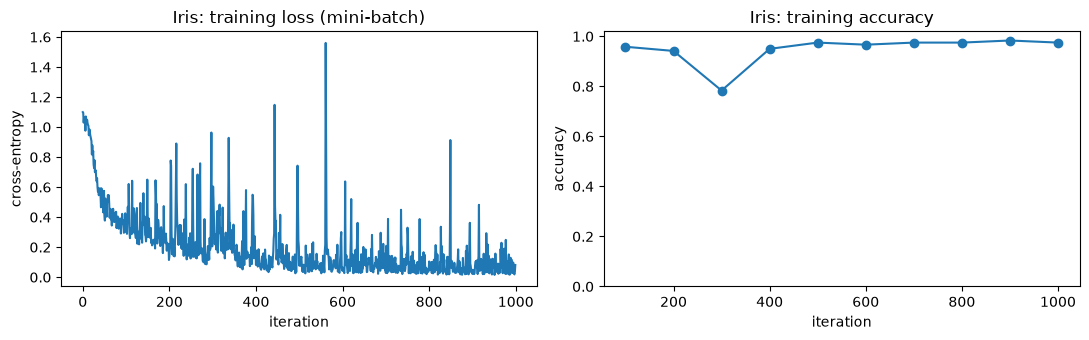

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(iris_loss_history)
ax[0].set(title="Iris: training loss (mini-batch)", xlabel="iteration", ylabel="cross-entropy")
iters_, accs_ = zip(*iris_acc_history)
ax[1].plot(iters_, accs_, marker="o")
ax[1].set(title="Iris: training accuracy", xlabel="iteration", ylabel="accuracy", ylim=(0, 1.02))
plt.tight_layout()
plt.show()


### 3.3 Save the trained network

In [11]:
iris_model_path = f"{LAST_NAME}_iris_nn_model.pkl"
save_network(
    iris_net, iris_model_path,
    dataset="iris", classes=IRIS_CLASSES, features=FEATURES,
    iterations=IRIS_ITERS, batch_size=IRIS_BATCH, learning_rate=IRIS_LR,
)
print("saved", iris_model_path, f"({Path(iris_model_path).stat().st_size} bytes)")


saved gujarathi_iris_nn_model.pkl (1187 bytes)


### 3.4 Load the saved network and test it

For every test sample: actual class, predicted class, and whether the prediction was correct.

In [12]:
loaded_iris_net, iris_meta = load_network(iris_model_path)

# the reloaded network must behave exactly like the one in memory
assert np.allclose(loaded_iris_net.predict(x_test_iris), iris_net.predict(x_test_iris))

pred_iris = np.argmax(loaded_iris_net.predict(x_test_iris), axis=1)
iris_results = pd.DataFrame({
    "sample": np.arange(1, len(y_test_iris) + 1),
    "actual": [IRIS_CLASSES[k] for k in y_test_iris],
    "predicted": [IRIS_CLASSES[k] for k in pred_iris],
    "result": np.where(pred_iris == y_test_iris, "correct", "incorrect"),
})
display(iris_results)

iris_test_acc = float(np.mean(pred_iris == y_test_iris))
print(f"Iris test accuracy: {int((pred_iris == y_test_iris).sum())}/{len(y_test_iris)} = {iris_test_acc:.4f}")

print("\nConfusion matrix (rows = actual, columns = predicted):")
display(pd.crosstab(pd.Series([IRIS_CLASSES[k] for k in y_test_iris], name="actual"),
                    pd.Series([IRIS_CLASSES[k] for k in pred_iris], name="predicted")))


,sample,actual,predicted,result
0,1,setosa,setosa,correct
1,2,setosa,setosa,correct
2,3,setosa,setosa,correct
3,4,setosa,setosa,correct
4,5,setosa,setosa,correct
5,6,setosa,setosa,correct
6,7,setosa,setosa,correct
7,8,setosa,setosa,correct
8,9,setosa,setosa,correct
9,10,setosa,setosa,correct


Iris test accuracy: 30/30 = 1.0000

Confusion matrix (rows = actual, columns = predicted):


predicted,setosa,versicolor,virginica
actual,,,
setosa,10,0,0
versicolor,0,10,0
virginica,0,0,10


## 4. Part 2: MNIST

### 4.1 Load the data

Pixels are scaled from 0-255 to 0-1; labels are one-hot encoded for training.

train: (60000, 784)  test: (10000, 784)
train class counts: [5923 6742 5958 6131 5842 5421 5918 6265 5851 5949]
test class counts:  [ 980 1135 1032 1010  982  892  958 1028  974 1009]


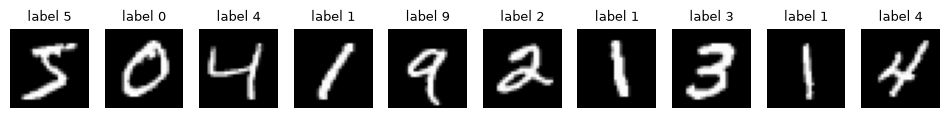

In [13]:
mnist = np.load(DATA_DIR / "mnist.npz")
x_train_mnist = mnist["x_train"].astype(np.float64) / 255.0
y_train_mnist = mnist["y_train"].astype(int)
t_train_mnist = np.eye(10)[y_train_mnist]
x_test_mnist = mnist["x_test"].astype(np.float64) / 255.0
y_test_mnist = mnist["y_test"].astype(int)

print("train:", x_train_mnist.shape, " test:", x_test_mnist.shape)
print("train class counts:", np.bincount(y_train_mnist))
print("test class counts: ", np.bincount(y_test_mnist))

fig, axes = plt.subplots(1, 10, figsize=(12, 1.8))
for k, a in enumerate(axes):
    a.imshow(x_train_mnist[k].reshape(28, 28), cmap="gray")
    a.set_title(f"label {y_train_mnist[k]}", fontsize=9)
    a.axis("off")
plt.show()


### 4.2 Train with the numerical gradient

In [14]:
MNIST_HIDDEN = 30
MNIST_ITERS = 300
MNIST_BATCH = 32
MNIST_LR = 1.0

rng = np.random.default_rng(0)
mnist_net = TwoLayerNet(784, MNIST_HIDDEN, 10, weight_init_std=0.1, seed=0)
n_params = sum(v.size for v in mnist_net.params.values())
print(f"parameters: {n_params}  ->  {2 * n_params} forward passes per numerical gradient")

# fixed subset of the training set used to monitor training accuracy
monitor_idx = rng.choice(len(x_train_mnist), 2000, replace=False)
x_monitor, t_monitor = x_train_mnist[monitor_idx], t_train_mnist[monitor_idx]
print(f"initial accuracy on monitor subset: {mnist_net.accuracy(x_monitor, t_monitor):.3f}")

mnist_loss_history, mnist_acc_history = [], []
print_every = max(MNIST_ITERS // 20, 1)
eval_every = max(MNIST_ITERS // 10, 1)
start = time.perf_counter()
for i in range(1, MNIST_ITERS + 1):
    mask = rng.choice(len(x_train_mnist), MNIST_BATCH)
    xb, tb = x_train_mnist[mask], t_train_mnist[mask]

    grad = mnist_net.numerical_gradient(xb, tb)
    for key in mnist_net.params:
        mnist_net.params[key] -= MNIST_LR * grad[key]

    mnist_loss_history.append(mnist_net.loss(xb, tb))
    if i % eval_every == 0:
        mnist_acc_history.append((i, mnist_net.accuracy(x_monitor, t_monitor)))
    if i % print_every == 0:
        msg = f"iter {i:4d}/{MNIST_ITERS}   batch loss {mnist_loss_history[-1]:.4f}"
        if i % eval_every == 0:
            msg += f"   train-subset accuracy {mnist_acc_history[-1][1]:.3f}"
        print(msg + f"   ({time.perf_counter() - start:.0f}s elapsed)")
print(f"training finished in {time.perf_counter() - start:.0f} seconds")


parameters: 23860  ->  47720 forward passes per numerical gradient
initial accuracy on monitor subset: 0.096
iter   15/300   batch loss 1.6164   (45s elapsed)
iter   30/300   batch loss 0.9701   train-subset accuracy 0.660   (91s elapsed)
iter   45/300   batch loss 0.7610   (137s elapsed)
iter   60/300   batch loss 0.5912   train-subset accuracy 0.820   (183s elapsed)
iter   75/300   batch loss 0.5134   (230s elapsed)
iter   90/300   batch loss 0.6322   train-subset accuracy 0.819   (277s elapsed)
iter  105/300   batch loss 0.4132   (323s elapsed)
iter  120/300   batch loss 0.4102   train-subset accuracy 0.858   (370s elapsed)
iter  135/300   batch loss 0.1615   (417s elapsed)
iter  150/300   batch loss 0.1473   train-subset accuracy 0.844   (465s elapsed)
iter  165/300   batch loss 0.3676   (512s elapsed)
iter  180/300   batch loss 0.1171   train-subset accuracy 0.891   (559s elapsed)
iter  195/300   batch loss 0.2161   (606s elapsed)
iter  210/300   batch loss 0.1908   train-subset a

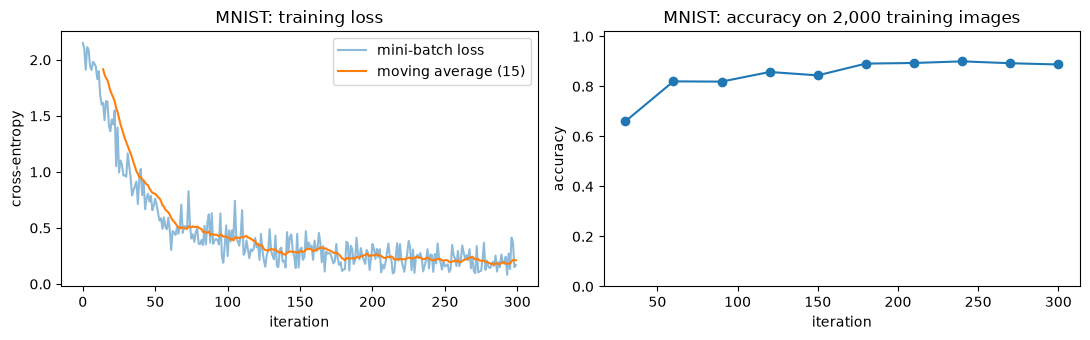

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(mnist_loss_history, alpha=0.5, label="mini-batch loss")
w = max(len(mnist_loss_history) // 20, 1)
smooth = np.convolve(mnist_loss_history, np.ones(w) / w, mode="valid")
ax[0].plot(np.arange(w - 1, len(mnist_loss_history)), smooth, label=f"moving average ({w})")
ax[0].set(title="MNIST: training loss", xlabel="iteration", ylabel="cross-entropy")
ax[0].legend()
iters_, accs_ = zip(*mnist_acc_history)
ax[1].plot(iters_, accs_, marker="o")
ax[1].set(title="MNIST: accuracy on 2,000 training images", xlabel="iteration", ylabel="accuracy", ylim=(0, 1.02))
plt.tight_layout()
plt.show()


### 4.3 Save the trained network

In [16]:
mnist_model_path = f"{LAST_NAME}_mnist_nn_model.pkl"
save_network(
    mnist_net, mnist_model_path,
    dataset="mnist", classes=list(range(10)), input_scaling="pixel / 255.0",
    iterations=MNIST_ITERS, batch_size=MNIST_BATCH, learning_rate=MNIST_LR,
)
print("saved", mnist_model_path, f"({Path(mnist_model_path).stat().st_size} bytes)")


saved gujarathi_mnist_nn_model.pkl (191363 bytes)


### 4.4 Load the saved network and test it

In [17]:
loaded_mnist_net, mnist_meta = load_network(mnist_model_path)
assert np.allclose(loaded_mnist_net.predict(x_test_mnist[:500]), mnist_net.predict(x_test_mnist[:500]))

pred_mnist = np.argmax(loaded_mnist_net.predict(x_test_mnist), axis=1)
correct = pred_mnist == y_test_mnist
mnist_test_acc = float(correct.mean())
print(f"MNIST test accuracy: {int(correct.sum())}/{len(correct)} = {mnist_test_acc:.4f}")

first = 20
display(pd.DataFrame({
    "test sample": np.arange(first),
    "actual": y_test_mnist[:first],
    "predicted": pred_mnist[:first],
    "result": np.where(correct[:first], "correct", "incorrect"),
}))
print(f"first {first} samples: {int(correct[:first].sum())}/{first} correct")


MNIST test accuracy: 8965/10000 = 0.8965


,test sample,actual,predicted,result
0,0,7,7,correct
1,1,2,2,correct
2,2,1,1,correct
3,3,0,0,correct
4,4,4,4,correct
5,5,1,1,correct
6,6,4,4,correct
7,7,9,9,correct
8,8,5,6,incorrect
9,9,9,9,correct


first 20 samples: 19/20 correct


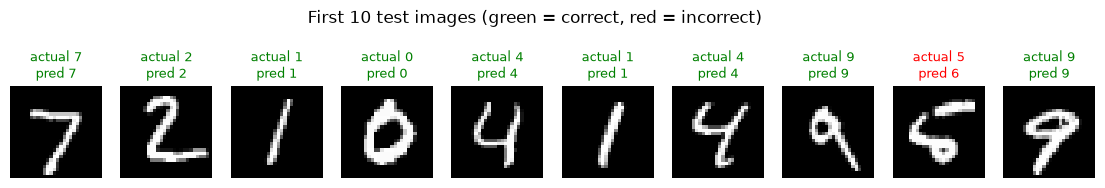

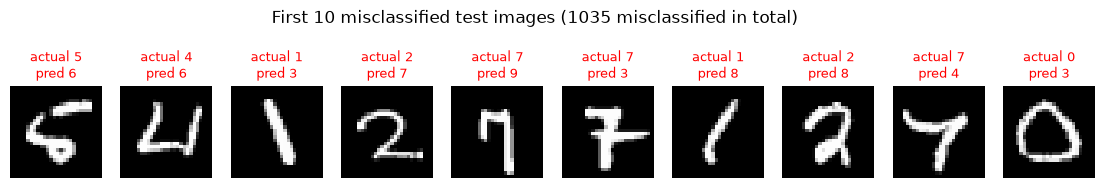

In [18]:
def show_samples(indices, title):
    fig, axes = plt.subplots(1, len(indices), figsize=(1.4 * len(indices), 2.2))
    for a, k in zip(np.atleast_1d(axes), indices):
        a.imshow(x_test_mnist[k].reshape(28, 28), cmap="gray")
        ok = pred_mnist[k] == y_test_mnist[k]
        a.set_title(f"actual {y_test_mnist[k]}\npred {pred_mnist[k]}", fontsize=9, color="green" if ok else "red")
        a.axis("off")
    fig.suptitle(title, y=1.05)
    plt.show()


show_samples(range(10), "First 10 test images (green = correct, red = incorrect)")
wrong = np.flatnonzero(~correct)
show_samples(wrong[:10], f"First 10 misclassified test images ({len(wrong)} misclassified in total)")


In [19]:
per_class = pd.DataFrame({
    "digit": range(10),
    "test samples": np.bincount(y_test_mnist, minlength=10),
    "correct": np.bincount(y_test_mnist[correct], minlength=10),
})
per_class["accuracy"] = (per_class["correct"] / per_class["test samples"]).round(3)
display(per_class)

print("Confusion matrix (rows = actual, columns = predicted):")
display(pd.crosstab(pd.Series(y_test_mnist, name="actual"), pd.Series(pred_mnist, name="predicted")))


,digit,test samples,correct,accuracy
0,0,980,948,0.967
1,1,1135,1079,0.951
2,2,1032,852,0.826
3,3,1010,915,0.906
4,4,982,835,0.850
5,5,892,721,0.808
6,6,958,891,0.930
7,7,1028,887,0.863
8,8,974,876,0.899
9,9,1009,961,0.952


Confusion matrix (rows = actual, columns = predicted):


predicted,0,1,2,3,4,5,6,7,8,9
actual,,,,,,,,,,
0,948,0,1,3,1,8,5,3,7,4
1,0,1079,0,8,1,1,4,1,41,0
2,16,7,852,34,18,1,19,13,61,11
3,5,0,11,915,0,18,3,9,32,17
4,1,2,2,0,835,0,10,1,4,127
5,14,2,2,54,14,721,21,5,38,21
6,24,3,1,1,15,14,891,0,8,1
7,3,10,23,9,6,0,0,887,3,87
8,5,2,1,23,7,13,12,5,876,30


## 5. Summary

In [20]:
summary = pd.DataFrame({
    "dataset": ["Iris", "MNIST"],
    "network": ["4-10-3", "784-30-10"],
    "training iterations": [IRIS_ITERS, MNIST_ITERS],
    "test samples": [len(y_test_iris), len(y_test_mnist)],
    "test accuracy": [round(iris_test_acc, 4), round(mnist_test_acc, 4)],
    "model file": [iris_model_path, mnist_model_path],
})
display(summary)


,dataset,network,training iterations,test samples,test accuracy,model file
0,Iris,4-10-3,1000,30,1.0000,gujarathi_iris_nn_model.pkl
1,MNIST,784-30-10,300,10000,0.8965,gujarathi_mnist_nn_model.pkl
